# Traces of spot F, tight cut, with the window of `integral` (-82 V, DCRC1pB trigger)

*Seventh notebook of `relcal`. Draft prepared with Claude Code for A. Villano, 2026-11-01.*

Randomly chosen events of the tight cut around spot F (within `TIGHT_F` = 0.5 us of its centre in the plane of the 20 % delays; see `spot-f-tight-energy.ipynb`), drawn in all channels, one tiled figure per event in the layout of the earlier notes (`pulse-normalization/small-physics-triggers-07221203_2025.ipynb`): one row per readout board (DCRC1, DCRC3, DCRC4), one column per board input (pA to pD); the inputs that are not sensors (the NaI trigger input DCRC4 pA and the free inputs) are blank. **The trigger of these series, DCRC1 pB, is the sensor Side2pF**, the channel of the centre disc.

**The window of `integral`** (`goldsluice`'s `integral`, the quantity summed into the energy of the energy notebooks) is drawn on every trace:

* the **baseline** is the mean of samples `glitch_samples` to `pretrigger_samples` (10 to 500; the grey band);
* the **integral** is the sum of (sample - baseline) over **the whole trace**, all 4096 samples, the glitch and baseline samples included, times the sample period (the shaded area, between the two dotted lines at the first and the last sample).

The traces are drawn with exactly that baseline subtracted, so the shaded area is the integral, and the value is recomputed here and checked against the processed one. The raw dumps are read from `~/idx`.

Needs `goldpan`, the output of `r76-82v-dcrc1pb.dataset.toml` in `~/goldsluice-output/r76-82v-dcrc1pb`, and the raw dumps in `~/idx`. Run with the `darkmatter_cli_env` kernel.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import goldpan.channels as pch
from goldpan.adapters import idx
from goldpan.config import DCRC_RUN76
from spots_82v import LETTERS, SPOTS, TIGHT_F, load

warnings.filterwarnings("once")
CONFIG = DCRC_RUN76                       # the readout of the registry record NAI-S2: 0.8 us, pretrigger window 500, 10 glitch samples
RAW = Path.home() / "idx"
N_EVENTS = 6                              # how many events to draw
SEED = 1                                  # change it for another random choice

d = load()
x0, y0, _ = SPOTS["F"]
tight = np.flatnonzero(d["use"] & (np.hypot(d["xdel"] - x0, d["ydel"] - y0) < TIGHT_F))
E = d["integral"].sum(axis=1)
chosen = np.sort(np.random.default_rng(SEED).choice(tight, N_EVENTS, replace=False))
print(f"{len(tight):,} events in the tight cut; chosen (seed {SEED}):")
for i in chosen:
    print(f"  {d['series'][i]} {d['dump'][i]} event {d['event'][i]}:  energy {E[i]:.2f}")

15,792 events in the tight cut; chosen (seed 1):
  07221111_2153 F0040 event 13356:  energy 8.94
  07221111_2153 F0054 event 10554:  energy 9.57
  07221112_0943 F0061 event 12487:  energy 11.88
  07221112_0943 F0068 event 11164:  energy 10.80
  07221112_2249 F0025 event 11605:  energy 6.82
  07221115_2109 F0033 event 12442:  energy 10.61


## Reading the traces

Each chosen event is read from its raw dump with the channel map of `goldpan.channels` (the Side-2 readout: the six sensors and where they are in the dump; the board order is inferred, see its warning). The integral is recomputed from the trace with the window above and compared with the processed value.

In [2]:
SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]                  # the tiles: three boards x four inputs
INFO = {k: pch.channel_info(*k) for k in KEYS}

def dump_dir(series, dump):
    return RAW / (dump if dump.startswith(series) else f"{series}_{dump}")

traces = {}                                                                # chosen index -> {channel name: raw trace}
for (s, dmp) in sorted({(d["series"][i], d["dump"][i]) for i in chosen}):
    ev = idx.read(dump_dir(s, dmp), detector_name="NAI-S2", channels=SENSORS, config=CONFIG)
    numbers = np.asarray(ev.quantities["event"])
    segment = {name: seg for (name, seg) in ev.traces}                    # the trace segment of each channel
    for i in chosen:
        if (d["series"][i], d["dump"][i]) == (s, dmp):
            j = int(np.flatnonzero(numbers == d["event"][i])[0])
            traces[i] = {name: np.asarray(ev.traces[(name, segment[name])][j], dtype=float) for name in SENSORS}

g, p = CONFIG.glitch_samples, CONFIG.pretrigger_samples
def baseline(x):
    return x[g:p].mean()

def integral(x):
    return (x - baseline(x)).sum() * CONFIG.sample_period_s

worst = max(abs(integral(traces[i][f"Side2p{k}"]) - d["integral"][i][n]) for i in chosen for n, k in enumerate(LETTERS))
print(f"largest difference between the recomputed and the processed integral: {worst:.2e} ADC counts x s")

C:\Users\Anthony\AppData\Local\Temp\ipykernel_22088\4260355021.py:1: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
C:\Users\Anthony\AppData\Local\Temp\ipykernel_22088\4260355021.py:3: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  INFO = {k: pch.channel_info(*k) for k in KEYS}


largest difference between the recomputed and the processed integral: 2.05e-13 ADC counts x s


## One figure per event

All channels of an event share one vertical scale, so they can be compared by eye. The time is measured from the trigger (sample 500). Each tile's title gives the channel, its board and its integral.

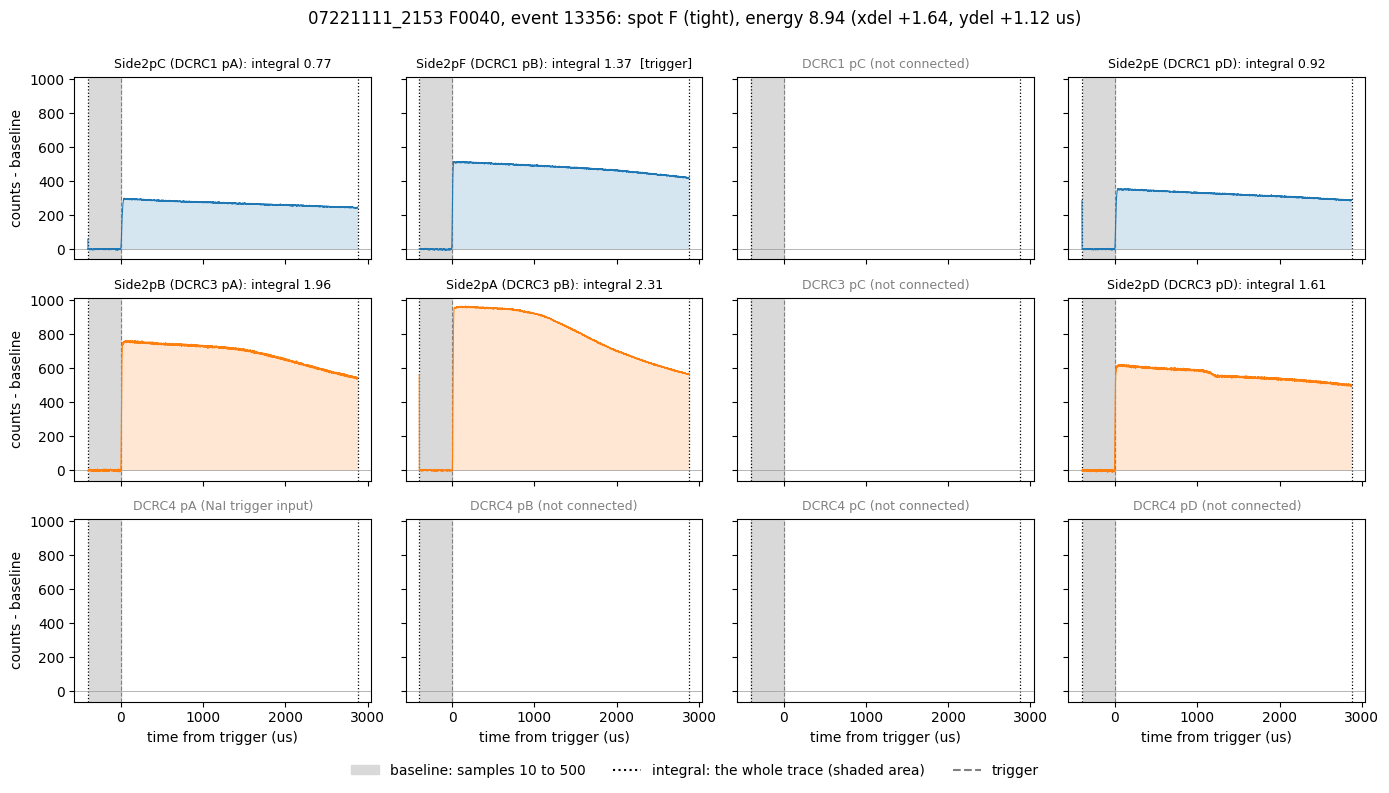

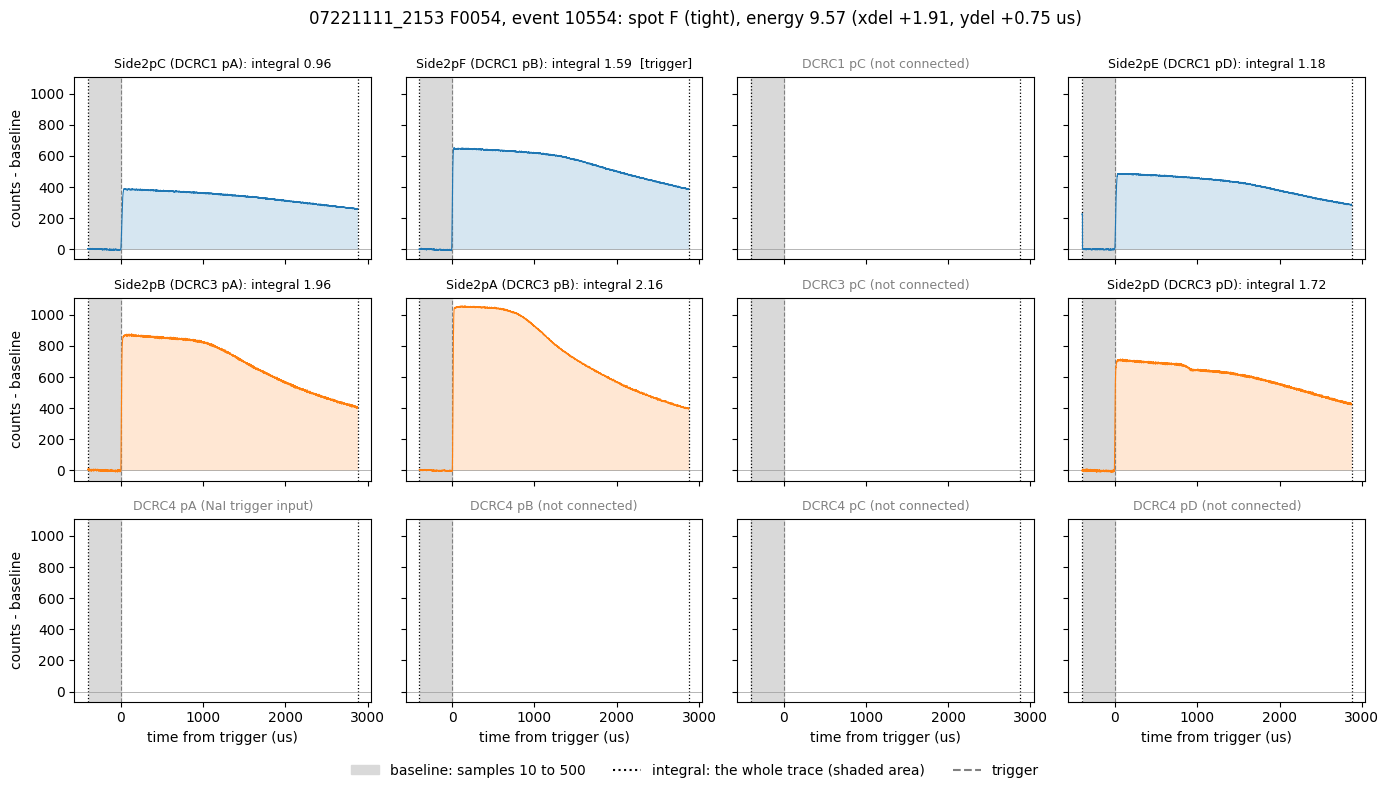

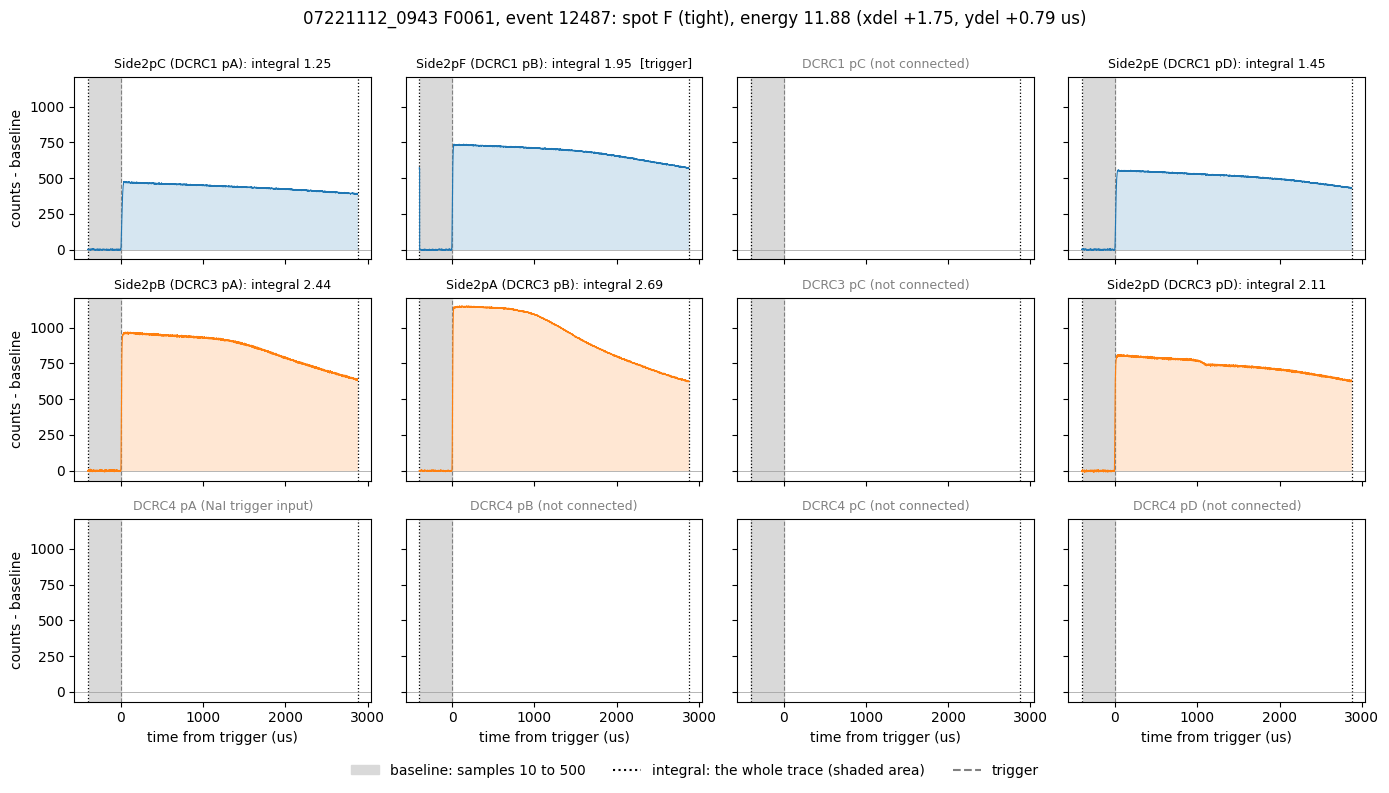

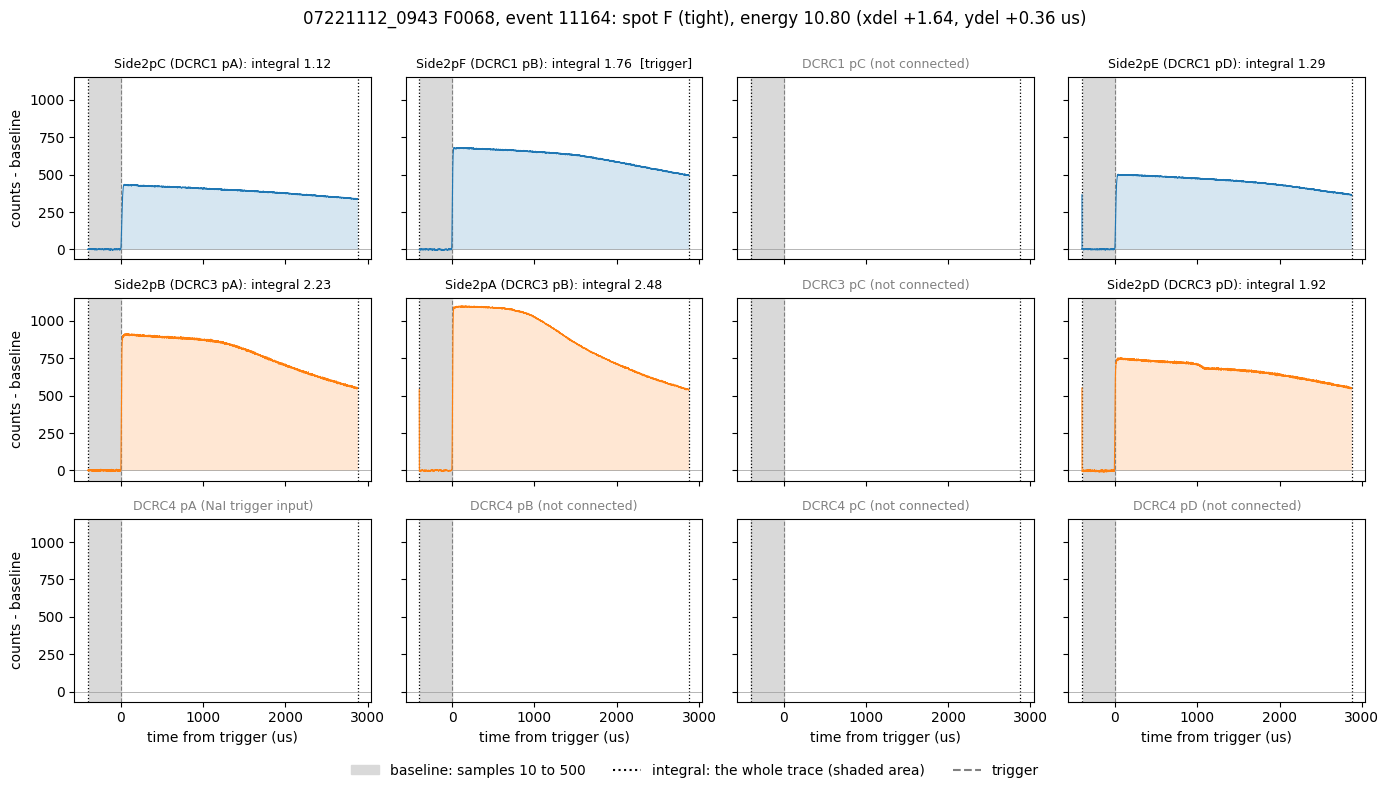

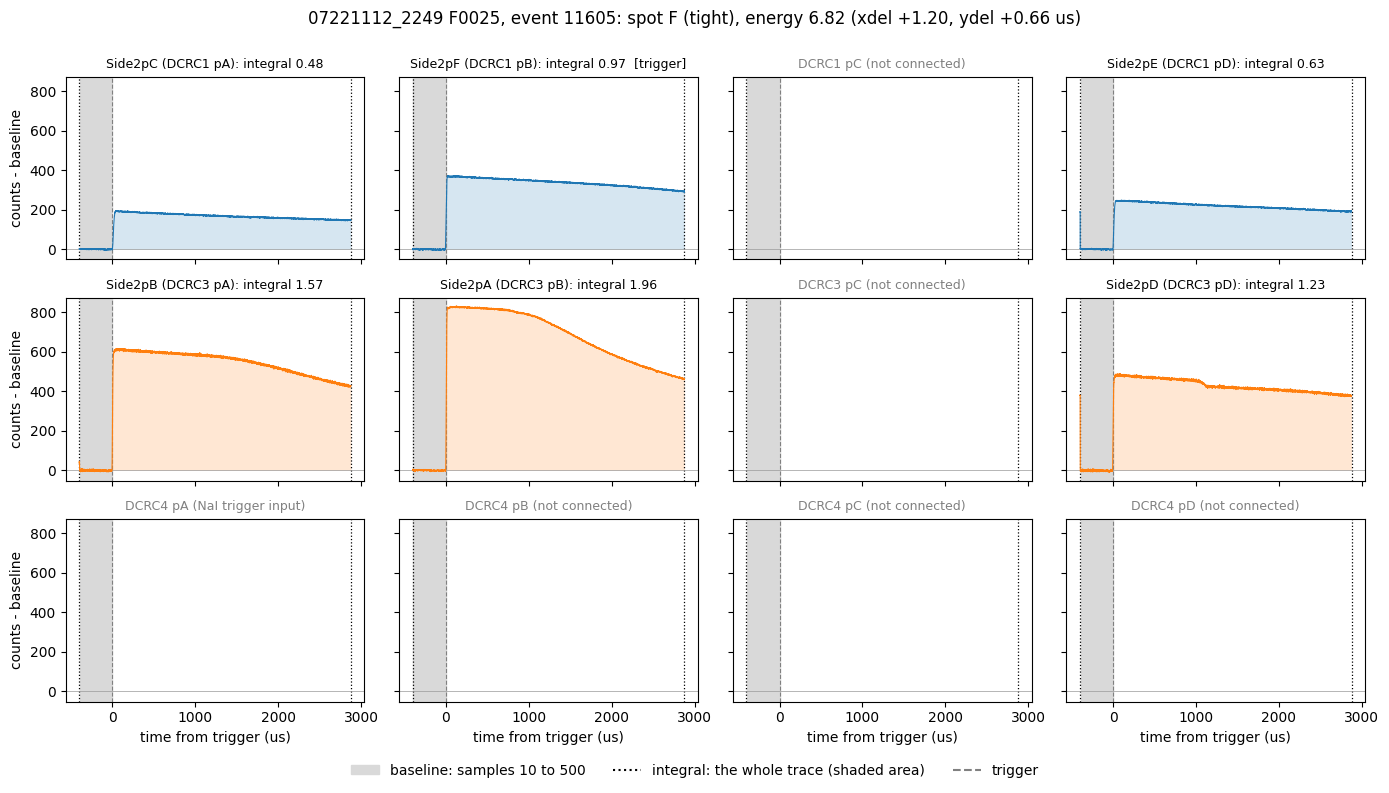

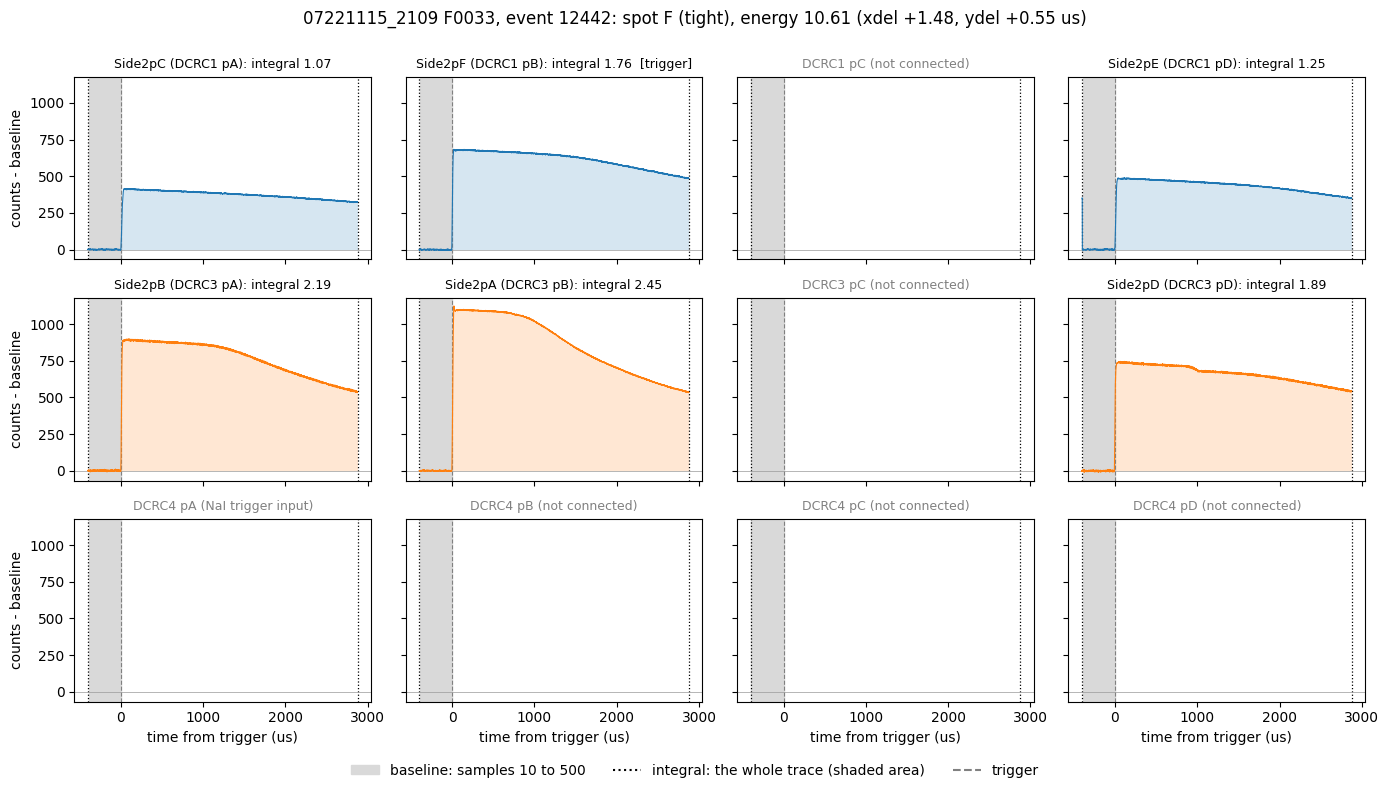

In [3]:
BOARD_COLOUR = {"DCRC1": "C0", "DCRC3": "C1"}      # one colour per readout board, as in the earlier notes
n_samples = len(next(iter(traces[chosen[0]].values())))
t_us = (np.arange(n_samples) - p) * CONFIG.sample_period_s * 1e6
t_base = ((g - p) * CONFIG.sample_period_s * 1e6, 0.0)               # the baseline window
t_ends = (t_us[0], t_us[-1])                                          # the integration window: the whole trace

def tiled(i, flats, title):
    lo = min(f.min() for f in flats.values())
    hi = max(f.max() for f in flats.values())
    pad = 0.05 * (hi - lo)
    fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey=True)
    for key, ax in zip(KEYS, axes.flat):
        c = INFO[key]
        ax.axvspan(*t_base, color="0.85", zorder=0)
        for t in t_ends:
            ax.axvline(t, color="k", linestyle=":", linewidth=0.9)
        ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
        ax.axhline(0, color="0.6", linewidth=0.5)
        if c.role != pch.SENSOR:
            what = "NaI trigger input" if c.role == pch.NAI_TRIGGER else "not connected"
            ax.set_title(f"{c.dcrc} {c.board_input} ({what})", fontsize=9, color="0.5")
            continue
        f = flats[c.name]
        colour = BOARD_COLOUR[c.dcrc]
        ax.fill_between(t_us, f, 0, color=colour, alpha=0.18, linewidth=0)
        ax.plot(t_us, f, linewidth=0.8, color=colour)
        trig = "  [trigger]" if (c.dcrc, c.board_input) == ("DCRC1", "pB") else ""
        ax.set_title(f"{c.name} ({c.dcrc} {c.board_input}): integral {f.sum() * CONFIG.sample_period_s:.2f}{trig}", fontsize=9)
    for ax in axes[-1]:
        ax.set_xlabel("time from trigger (us)")
    for ax in axes[:, 0]:
        ax.set_ylabel("counts - baseline")
    axes[0, 0].set_ylim(lo - pad, hi + pad)
    fig.suptitle(title, y=1.0)
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="0.85", label=f"baseline: samples {g} to {p}"),
                        plt.Line2D([], [], color="k", linestyle=":", label="integral: the whole trace (shaded area)"),
                        plt.Line2D([], [], color="0.5", linestyle="--", label="trigger")],
               loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04), frameon=False)
    fig.tight_layout()
    plt.show()

for i in chosen:
    flats = {name: x - baseline(x) for name, x in traces[i].items()}
    tiled(i, flats, f"{d['series'][i]} {d['dump'][i]}, event {d['event'][i]}: spot F (tight), energy {E[i]:.2f} "
                    f"(xdel {d['xdel'][i]:+.2f}, ydel {d['ydel'][i]:+.2f} us)")

## All the chosen events together

The same tiles with every chosen event overlaid (one shade per event), to see how much the pulses of the spot differ from each other.

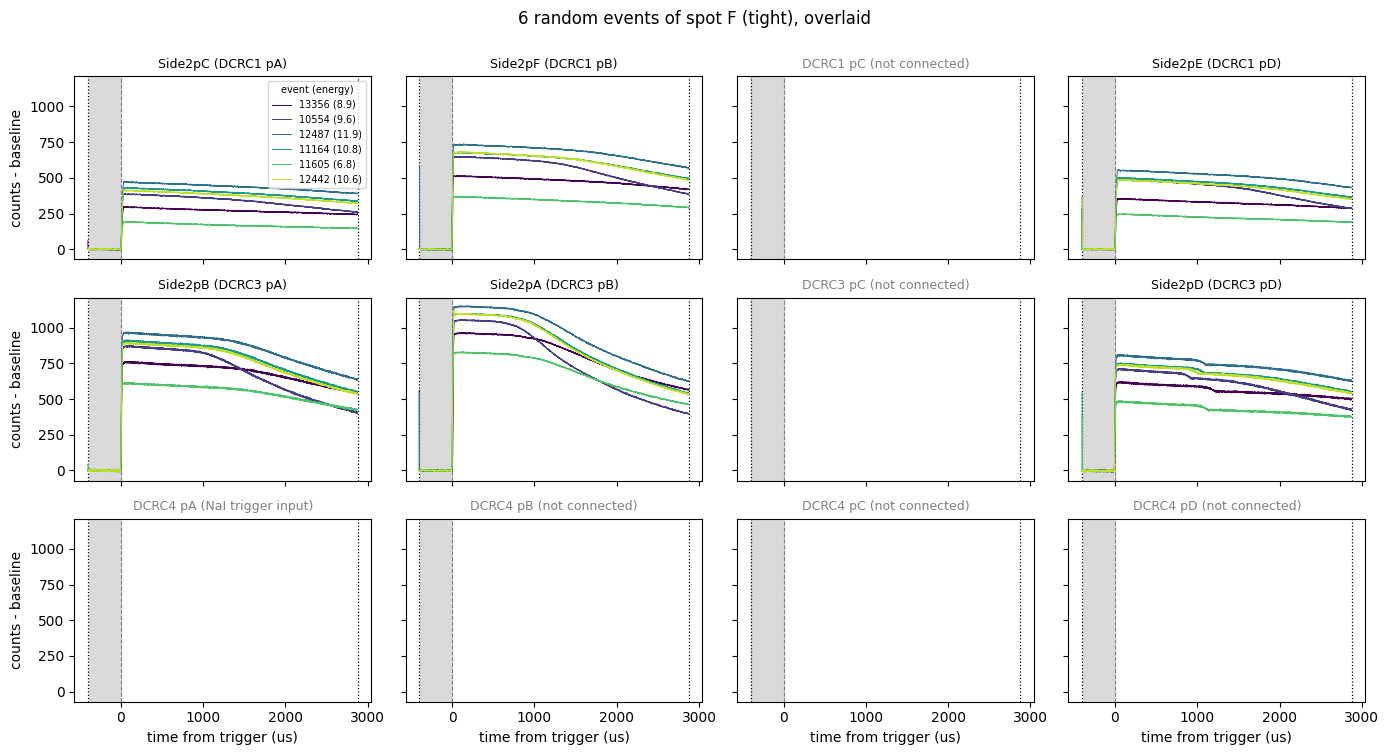

In [4]:
fig, axes = plt.subplots(3, 4, figsize=(14, 7.5), sharex=True, sharey=True)
shades = plt.get_cmap("viridis")(np.linspace(0, 0.9, len(chosen)))
for key, ax in zip(KEYS, axes.flat):
    c = INFO[key]
    ax.axvspan(*t_base, color="0.85", zorder=0)
    for t in t_ends:
        ax.axvline(t, color="k", linestyle=":", linewidth=0.9)
    ax.axvline(0, color="0.5", linestyle="--", linewidth=0.8)
    if c.role != pch.SENSOR:
        what = "NaI trigger input" if c.role == pch.NAI_TRIGGER else "not connected"
        ax.set_title(f"{c.dcrc} {c.board_input} ({what})", fontsize=9, color="0.5")
        continue
    for i, col in zip(chosen, shades):
        x = traces[i][c.name]
        ax.plot(t_us, x - baseline(x), linewidth=0.7, color=col, label=f"{d['event'][i]} ({E[i]:.1f})")
    ax.set_title(f"{c.name} ({c.dcrc} {c.board_input})", fontsize=9)
for ax in axes[-1]:
    ax.set_xlabel("time from trigger (us)")
for ax in axes[:, 0]:
    ax.set_ylabel("counts - baseline")
axes[0, 0].legend(title="event (energy)", fontsize=7, title_fontsize=7)
fig.suptitle(f"{len(chosen)} random events of spot F (tight), overlaid", y=1.0)
fig.tight_layout()
plt.show()

**What to look for.** Whether the pulses of the spot are saturated (a flat top in every channel, see the discussion of the upper edge of the energy distributions), how long the flat top lasts, and how much of the integral comes from the part of the trace after the pulse has fallen. The integral runs to the end of the trace whatever the pulse does, so a pulse that has not returned to the baseline by the last sample is cut off there; the window does not adapt to the pulse.